# Práctica: _Quantum Phase Estimation_

## Importación de Bibliotecas

In [80]:
from math import pi
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import ZGate, SGate, TGate, RZGate
from qiskit.circuit import Gate

import matplotlib
import matplotlib.pyplot as plt

## Ejercicio 1

### Consigna

Implemente el QPE visto en el curso considerando diferentes operadores unitarios de rotación U y diferentes cantidades de qubits objetivo (m) y qubits de estimación (t):

i. U = Z; U = S; U = T; U = Rz(𝝅); U = Rz(𝝅/2); U = Rz(𝝅/4); U = Rz(3𝝅/4); (m = 1 y t = 4)
ii. inciso i) con m = 2
iii. inciso i) con t = 6
iv. U = Rz(-𝝅/4); U = Rz(-3𝝅/4); (m = 1 y t = 4)

### Resolución

#### Transformada Inversa de Fourier

Como paso previo a la implementación del algoritmo QPE, se requiere implementar la transformada inversa cuántica de fourier ($QFT^{-1}$).

Dicha implementación puede extraerse de las resoluciones de los prácticos anteriores.

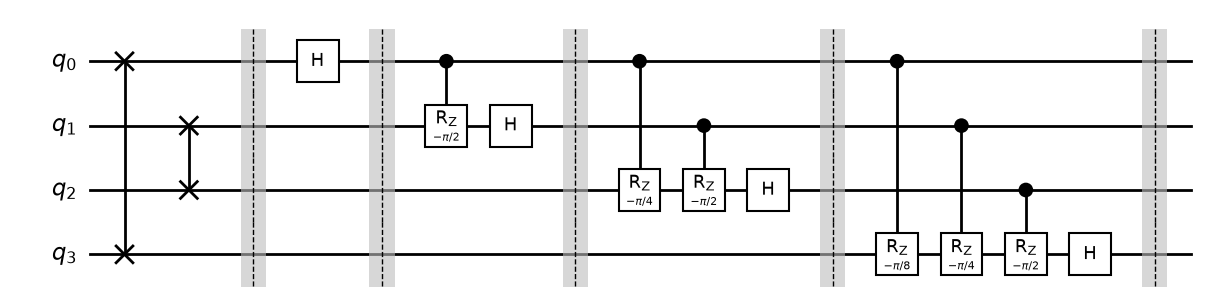

In [81]:
def iqtf(number_of_qubits):
    
    quantum_circuit = QuantumCircuit(number_of_qubits, name="IQTF")
    
    accesible_qubits = number_of_qubits - 1
    
    # Swap entre el qubit 0 y el n - 1.
    # Swap entre el qubit 1 y el n - 2.
    # Y así hasta llegar al centro.
    
    # Los swaps pueden ahorrarse si se invierte el orden de los qubits resultados.
    for i in range(int(number_of_qubits/2)):
        quantum_circuit.swap(i, accesible_qubits - i)
        
    quantum_circuit.barrier()
        
    # Por cada qubit, se aplica una rotación extra.
    # Al primer qubit, solo se le aplica Hadamard.
    # Al segundo, una rotación de pi/2 y Hadamard.
    # Al tercero, una rotación de pi/4, una rotación de pi/2 y Hadamard.
    for i in range(number_of_qubits):
        
        for j in range(i, 0, -1):
            # crz(angulo, control, objetivo)
            quantum_circuit.crz(-pi/(2 ** j), i - j, i)
        
        # Se aplica un Hadamard luego de las rotaciones.
        quantum_circuit.h(i)
        
        # Se aplica una barrera para evitar el autoordenamiento de Qiskit.
        quantum_circuit.barrier()
        
    return quantum_circuit
        
qc = iqtf(4)
qc.draw(output='mpl', style='bw')

#### QPE

A continuación, se define una función que, dado un número de qubits objetivos ($m$), un número de qubits de estimación ($t$) y un ángulo de rotación $\alpha$, devuelve la implementación del QPE correspondiente.

In [82]:
def qpe(qubits_objetivo: int, qubits_estimacion: int, operador_unitario: Gate) -> QuantumCircuit:
    
    qubits_totales: int = qubits_objetivo + qubits_estimacion
    
    quantum_circuit = QuantumCircuit(qubits_totales, name="QPE")
    
    # Se le aplica Hadamard a cada qubit de estimación.
    for i in range(qubits_estimacion):
        quantum_circuit.h(i)
    
    # Operadores unitarios controlados.
    for i in range(qubits_estimacion):
        controlled_u = (operador_unitario ** (2 ** i)).control(1)

        for j in range(qubits_estimacion, qubits_totales):
            quantum_circuit.append(controlled_u, [i, j])
            
    # Aplicación de la transformada cuántica inversa de Fourier.
    quantum_circuit.append(iqtf(qubits_estimacion), range(0, qubits_estimacion))
    
    return quantum_circuit

##### Inciso I)

$m = 1$ y $t = 4$

In [83]:
m = 1
t = 4

Se define una función para obtener los distintos operadores unitarios de rotación $U$ descritos en el enunciado:

In [84]:
def get_unitary_rotation_operator(operator: str) -> Gate:
    operators = {
        "Z": ZGate(),
        "S": SGate(),
        "T": TGate(),
        "Rz(π)": RZGate(pi),
        "Rz(π/2)": RZGate(pi / 2),
        "Rz(π/4)": RZGate(pi / 4),
        "Rz(3π/4)": RZGate(3 * pi / 4),
        "Rz(-π/4)": RZGate(-pi / 4),
        "Rz(-3π/4)": RZGate(-3 * pi / 4),
    }

    if operator not in operators:
        raise ValueError(f"Unsupported operator: {operator}")

    return operators[operator]

In [85]:
def simulate(qc: QuantumCircuit, shots: int = 1024):
    measured_qc = qc.copy()
    measured_qc.measure_all()

    simulator = AerSimulator()
    compiled_qc = transpile(measured_qc, simulator)

    result = simulator.run(compiled_qc, shots=shots).result()

    return result.get_counts()

Se evalúa el circuito para cada uno de los operadores unitarios descritos en el inciso:

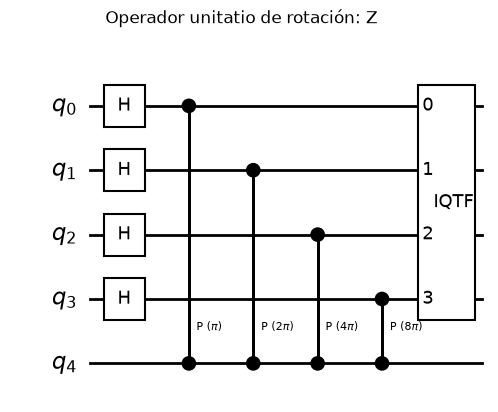

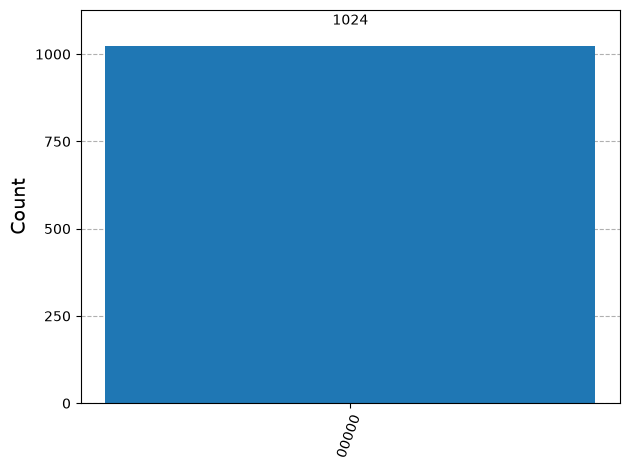

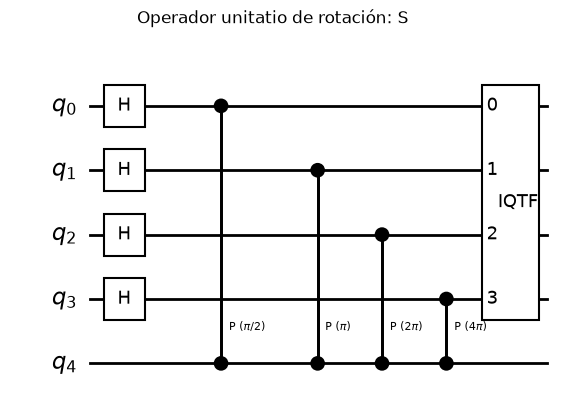

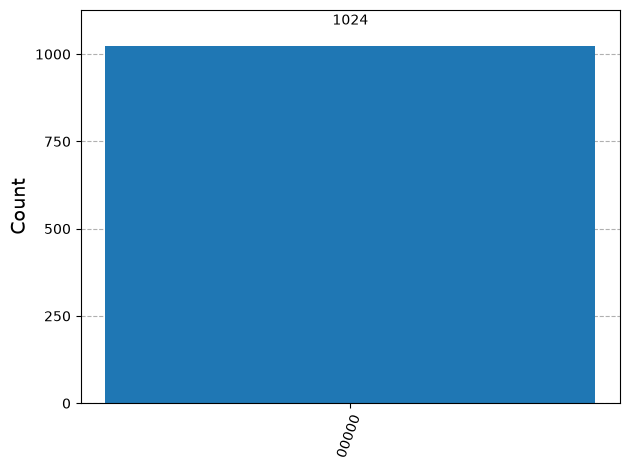

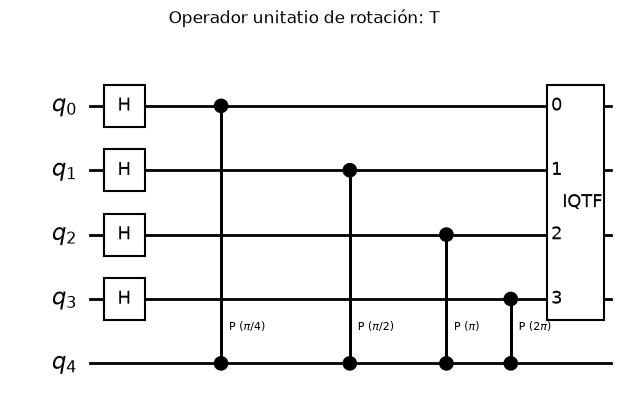

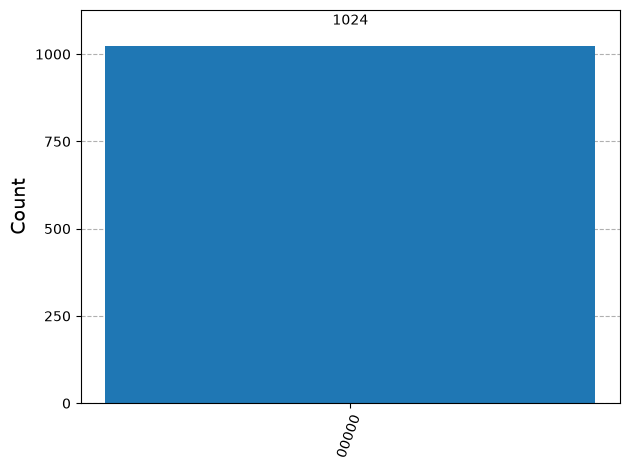

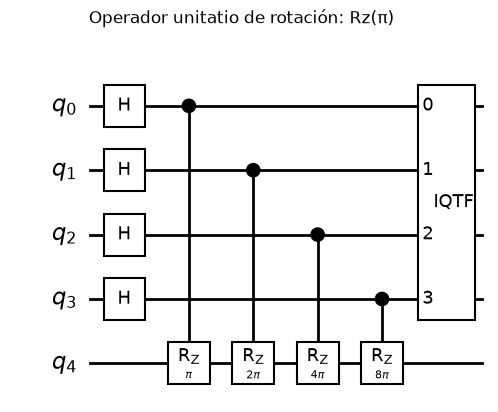

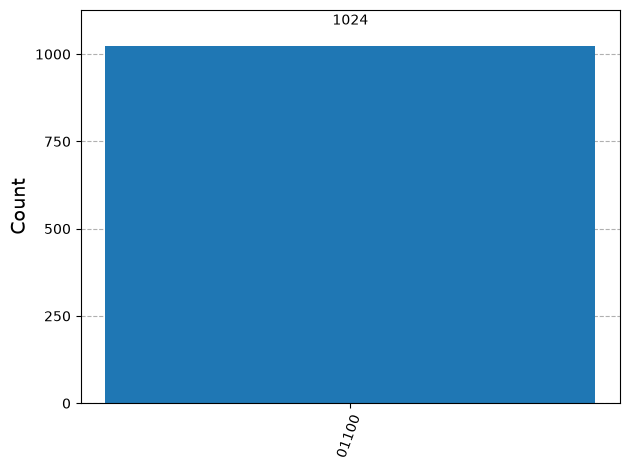

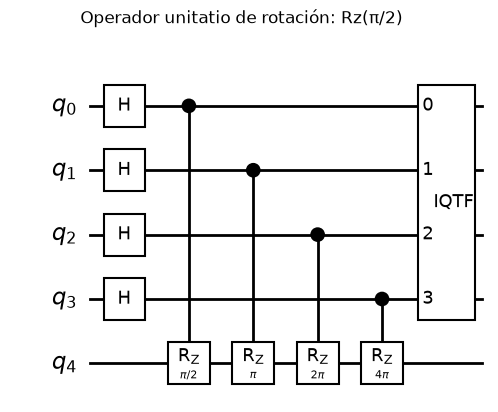

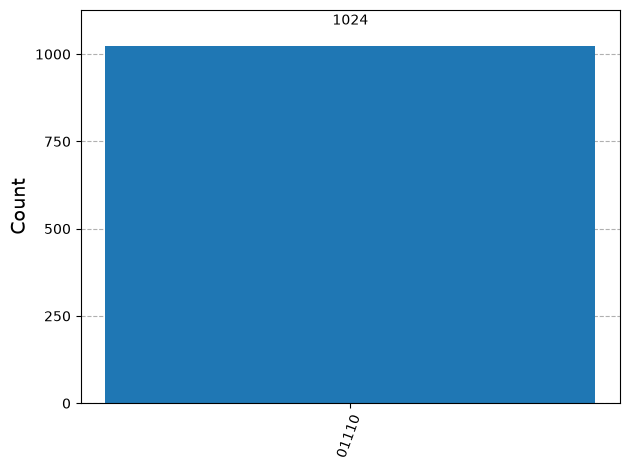

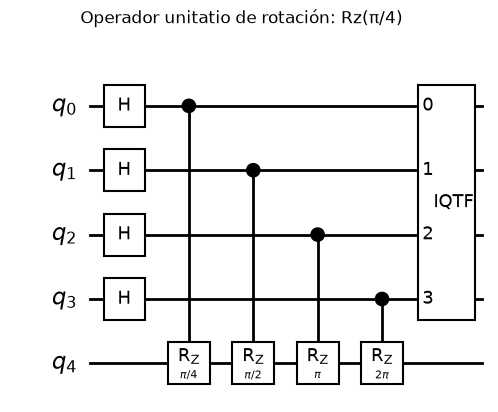

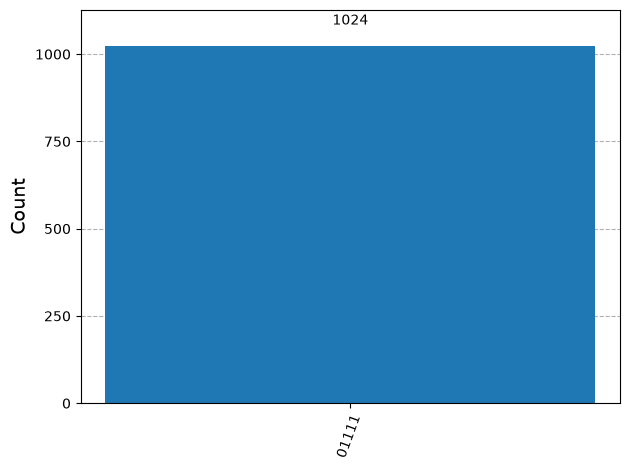

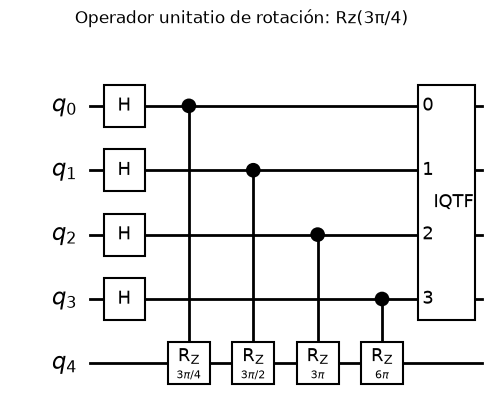

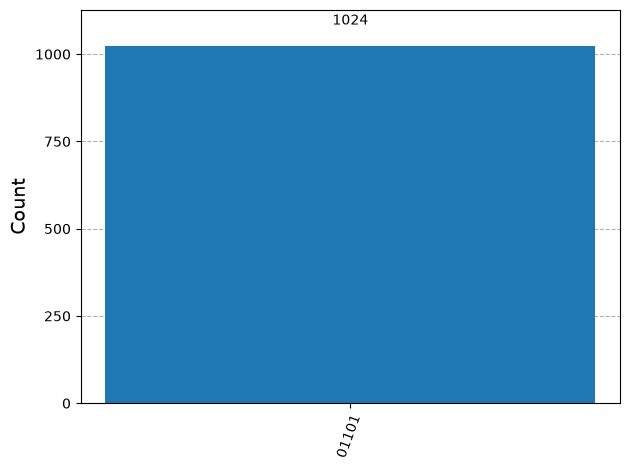

In [86]:
unitary_rotation_operators = ["Z", "S", "T", "Rz(π)", "Rz(π/2)", "Rz(π/4)", "Rz(3π/4)"]

for operator in unitary_rotation_operators:
    qc = qpe(m, t, get_unitary_rotation_operator(operator))

    fig = qc.draw(output="mpl", style="bw")
    fig.suptitle(f"Operador unitatio de rotación: {operator}")
    display(fig)
    
    counts = simulate(qc, 1024)
    
    display(plot_histogram(counts))

## Ejercicio 2

### Consigna

Analice para el ejercicio 1.i) el impacto de la fase global en los autovalores

### Resolución